# 05 · Deep learning vs LightGBM

**The question.** Practitioners often say that, with the right training settings, deep learning can match gradient-boosted
trees on retail demand (claim 4 in notebook 01). With the recipe's settings, how do two deep models, N-HiTS and TCN, compare with a LightGBM baseline (LGBM in the
table and text below) on the same series, the same origins and the same Tweedie loss?

In [1]:
import sys, os
try: import m5knobs  # noqa: F401  (installed with pip install -e .)
except ImportError: sys.path.insert(0, os.path.abspath(".."))  # run from notebooks/
from m5knobs import data, paths, results
from m5knobs.figures import architectures

## Setup

Every model is refit at every origin. LGBM is direct (one model per lead week) with lags 1 to 26, rolling mean, standard
deviation, max and min over 4, 13, 26 and 52 weeks, an expanding mean, and calendar features, all from stock `mlforecast`
transforms. The deep models use the recipe from notebook 02. The p-value is a paired bootstrap over series on WAPE; a gap smaller
than the seed-noise bar (notebook 01) is read as "within seed noise" whatever its p-value. The same approximate bar is
applied to all three models. A deep model counts as level with or better than LGBM
when its read is "within seed noise" or "better".

In [2]:
from m5knobs import baselines
from IPython.display import Markdown, display
lgbm = baselines.make_lgbm(seed=1).models["yhat"].get_params()
display(Markdown(f"LGBM settings, from `m5knobs/baselines.py`: `objective='{lgbm['objective']}'`, "
                 f"`tweedie_variance_power={lgbm['tweedie_variance_power']}` (the deep models' `tweedie_rho` is "
                 f"{data.RECIPE['tweedie_rho']}), `n_estimators={lgbm['n_estimators']}`, `num_leaves={lgbm['num_leaves']}`. "
                 f"Direct strategy: {data.H} models per origin, one per lead week, refit at each of the "
                 f"{data.NFOLDS} origins."))

LGBM settings, from `m5knobs/baselines.py`: `objective='tweedie'`, `tweedie_variance_power=1.5` (the deep models' `tweedie_rho` is 1.5), `n_estimators=200`, `num_leaves=127`. Direct strategy: 13 models per origin, one per lead week, refit at each of the 3 origins.

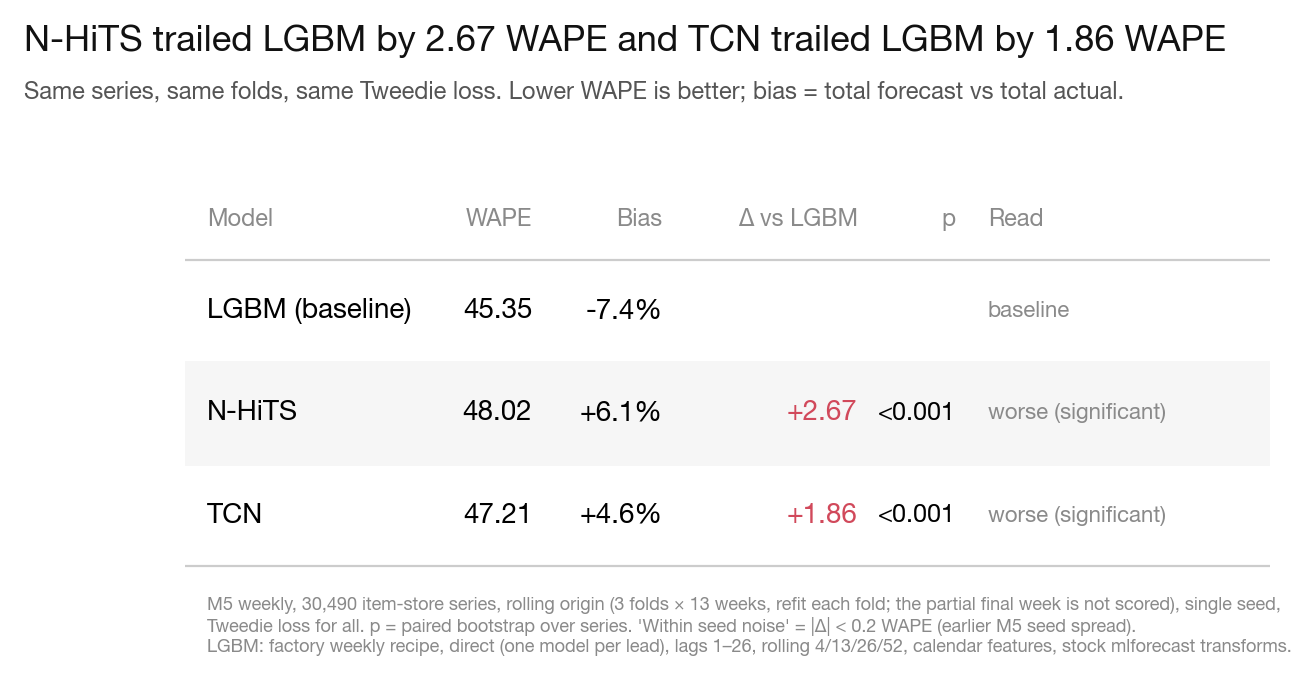

In [3]:
from IPython.display import Image, Markdown, display
display(Image(architectures.draw()[0], width=800))

In [4]:
import pandas as pd
t = pd.read_csv(os.path.join(paths.RESULTS, "f4_table.csv"))
runs = {name: results.load_run(arm)["summary"] for name, arm in architectures.ROWS}
minutes = {n: sum(f["fit_seconds"] for f in s["fold_stats"]) / 60 for n, s in runs.items()}
t["fit minutes, all origins"] = t["model"].map(minutes).round(1)
t["device"] = t["model"].map({n: s.get("accelerator", "cpu" if n.startswith("LGBM") else "not recorded")
                              for n, s in runs.items()})
display(t.round(3))

,model,wape,bias,gap_vs_lgbm,p_vs_lgbm,read,"fit minutes, all origins",device
0,LGBM (baseline),45.345,-7.438,NaN,NaN,baseline,14.9,cpu
1,N-HiTS,48.016,6.115,2.671,0.0,worse (significant),16.2,mps
2,TCN,47.208,4.647,1.863,0.0,worse (significant),30.9,mps


In [5]:
unknown = int((t["device"] == "not recorded").sum())
display(Markdown(f"Device not recorded for {unknown} of {len(t)} models (see the table); compare fit times roughly."
                 if unknown else "Fit time depends on the device; each run's device is in the table."))

Fit time depends on the device; each run's device is in the table.

## Read per model

In [6]:
b, pf = t.iloc[0], lambda p: "<0.001" if p < 0.001 else f"{p:.3f}"
for r in t.iloc[1:].itertuples():
    side = "closer to" if abs(r.bias) < abs(b.bias) else "further from"
    display(Markdown(f"- **{r.model}**: WAPE {r.wape:.2f} vs {b.wape:.2f} for LGBM (gap {r.gap_vs_lgbm:+.2f}, "
                     f"p {pf(r.p_vs_lgbm)}): {r.read}. Bias {r.bias:+.1f}% vs {b.bias:+.1f}%, {side} zero."))
display(Markdown(f"{architectures.headline_text(t)}. {architectures.claim_text(t)}"))

- **N-HiTS**: WAPE 48.02 vs 45.35 for LGBM (gap +2.67, p <0.001): worse (significant). Bias +6.1% vs -7.4%, closer to zero.

- **TCN**: WAPE 47.21 vs 45.35 for LGBM (gap +1.86, p <0.001): worse (significant). Bias +4.6% vs -7.4%, closer to zero.

N-HiTS trailed LGBM by 2.67 WAPE and TCN trailed LGBM by 1.86 WAPE. No deep model was level with or better than LGBM on WAPE. Verdict on the claim: does not hold.

## Slow sellers and the Tweedie floor

Notebook 02 showed that the Tweedie link keeps the forecast mean at or above about one unit a week, in sales units. The
deep forecasts are the mean of sampled values, so they scatter around that mean. The cell below looks at series that sold
under one unit a week on average in the 52 weeks before the first origin.

In [7]:
if os.path.exists(paths.M5_WEEKLY):
    p, c0 = data.load_panel(), pd.Timestamp(data.CUTOFFS[0])
    rate = p[(p.ds <= c0) & (p.ds > c0 - pd.Timedelta(weeks=52))].groupby("unique_id")["y"].mean()
    slow = set(rate[rate < 1].index)
    rows = []
    for name, arm in architectures.ROWS:
        r = results.load_run(arm)
        ps, fc = r["ps"][r["ps"].unique_id.isin(slow)], r["fc"][r["fc"].unique_id.isin(slow)]
        rows.append({"model": name, "bias on slow sellers (%)": 100 * (ps.yhat_sum.sum() / ps.y_sum.sum() - 1),
                     "median weekly forecast": fc.yhat.median(), "forecasts under 0.9 units (%)": 100 * (fc.yhat < 0.9).mean()})
    allps = results.load_run("f4_lgbm")["ps"]
    vol = allps[allps.unique_id.isin(slow)].y_sum.sum() / allps.y_sum.sum()
    display(Markdown(f"{len(slow):,} of the {len(rate):,} series with history before the first origin "
                     f"({len(slow) / len(rate):.0%}) sold under one unit a week; "
                     f"they hold {vol:.1%} of scored volume."))
    display(pd.DataFrame(rows).set_index("model").round(2))
else:
    print("data/m5_weekly.parquet not found: run `python3 scripts/prepare_data.py` to see the slow-seller table.")

4,189 of the 30,408 series with history before the first origin (14%) sold under one unit a week; they hold 2.4% of scored volume.

,bias on slow sellers (%),median weekly forecast,forecasts under 0.9 units (%)
model,,,
LGBM (baseline),-18.88,0.80,59.40
N-HiTS,-9.06,1.01,0.05
TCN,-1.96,1.01,0.06


## What to set

In [8]:
dl = t.iloc[1:].sort_values("wape").iloc[0]
display(Markdown(f"""- With the recipe, start from {dl.model}, the deep model with the lower WAPE here ({dl.wape:.2f}), and keep LGBM as the baseline it has to beat.
- Compare model families on the same series, origins and loss, refit at every origin, and report WAPE with bias.
- Treat a WAPE gap inside the seed-noise bar (±{data.SEED_NOISE['wape']}) as a tie unless you have several seeds."""))

- With the recipe, start from TCN, the deep model with the lower WAPE here (47.21), and keep LGBM as the baseline it has to beat.
- Compare model families on the same series, origins and loss, refit at every origin, and report WAPE with bias.
- Treat a WAPE gap inside the seed-noise bar (±0.2) as a tie unless you have several seeds.

Next: [06 · Summary](06_summary.ipynb).